# 05 — Modelo final: selección, configuración, umbral y evaluación
[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/AlejandroP212/ML2-Proyecto-Riesgo-Crediticio/blob/main/notebooks/05_modelo_final.ipynb)

**Integrantes:** David Castro & Alejandro Pardo
**Asignatura:** Machine Learning II — Universidad Externado de Colombia

Corresponde a la sección **8.1 Modelo final y reproducción del método del artículo** de la Entrega final:

1. Selección del modelo final a partir de la comparación validada del notebook 03 (sección 1).
2. Configuración definitiva y estabilidad de su hiperparámetro (sección 2).
3. Umbral de decisión elegido **sin usar la prueba** (sección 3).
4. Evaluación única en el conjunto de prueba (sección 4).
5. Contraste con el método y los resultados del artículo (sección 5).
6. Probabilidades interpretables para el despliegue (sección 6).
7. Artefactos para el despliegue: modelo, contrato de entrada y predicción de referencia (sección 7).

In [1]:
# === Configuración de rutas (funciona en Colab y en local) ===
import os, sys
from pathlib import Path

if "google.colab" in sys.modules and not Path("ML2-Proyecto-Riesgo-Crediticio").exists():
    !git clone -q https://github.com/AlejandroP212/ML2-Proyecto-Riesgo-Crediticio.git
    os.chdir("ML2-Proyecto-Riesgo-Crediticio")

ROOT = Path.cwd()
while not (ROOT / "CHECKSUMS.txt").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
DATA, FIGS, TABLES, MODELS = ROOT / "data", ROOT / "figuras", ROOT / "resultados", ROOT / "modelos"
for d in (DATA, FIGS, TABLES, MODELS):
    d.mkdir(exist_ok=True)
SEED = 42
print("Raíz del proyecto encontrada:", ROOT.name)

Raíz del proyecto encontrada: ml2-proyecto-riesgo-crediticio


In [2]:
import json, platform
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import sklearn
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV, cross_val_predict, validation_curve
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (balanced_accuracy_score, accuracy_score, recall_score, precision_score, f1_score,
                             roc_auc_score, confusion_matrix, ConfusionMatrixDisplay)

plt.style.use("seaborn-v0_8-whitegrid")
ruta = DATA / "credito_colombia_simulado.csv"
if not ruta.exists():  # si no se ejecutó el notebook 01, se genera aquí
    from src.simulacion_credito import generar_dataset_credito_colombia
    generar_dataset_credito_colombia(6000, SEED).to_csv(ruta, index=False)
df = pd.read_csv(ruta)

X, y = df.drop(columns="incumple"), df["incumple"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=SEED, stratify=y)
cv5 = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
print(f"Train: {len(X_train)} | Test: {len(X_test)} | mora: {y_train.mean():.2%}")

Train: 4800 | Test: 1200 | mora: 8.50%


## 1. Selección del modelo final
La guía pide elegir el modelo final con base en **métricas, estabilidad y equilibrio entre desempeño e
interpretabilidad**. Se parte de la comparación de los nueve modelos del artículo en igualdad de condiciones
(notebook 03, CV anidada 5 × 3).

In [3]:
tabla3 = pd.read_csv(TABLES / "tabla3_comparacion_equitativa.csv")
tabla3 = tabla3.dropna(subset=["CV anidada Bal. Acc (media)"]).sort_values("CV anidada Bal. Acc (media)", ascending=False)
tabla3[["Modelo", "CV anidada Bal. Acc (media)", "CV anidada Bal. Acc (desv)", "Test Bal. Acc", "Test ROC-AUC"]]

,Modelo,CV anidada Bal. Acc (media),CV anidada Bal. Acc (desv),Test Bal. Acc,Test ROC-AUC
1,Regresión Logística,0.8924,0.0082,0.8994,0.9628
3,SVM,0.8912,0.0049,0.8964,0.9595
5,Random Forest,0.8909,0.0109,0.8659,0.9434
9,LightGBM,0.8908,0.0096,0.8833,0.9513
8,XGBoost,0.8905,0.0102,0.8588,0.9501
7,Gradient Boosting,0.8878,0.0066,0.8890,0.9541
6,AdaBoost,0.8797,0.0154,0.8705,0.9502
4,Árbol de Decisión,0.8572,0.0155,0.8573,0.8747
2,Naïve Bayes,0.7835,0.0245,0.7911,0.9506


**Decisión: Regresión Logística.**

| Criterio de la guía | Evidencia |
|---|---|
| Métricas | Mayor balanced accuracy media en CV anidada (0,892). Los siete primeros modelos están empatados: las diferencias (≤ 0,012) son menores que la variación entre pliegues. |
| Estabilidad | Desviación entre pliegues de 0,008, de las más bajas; su desempeño casi no cambia con el hiperparámetro C (sección 2). |
| Interpretabilidad | Es el modelo más interpretable de los empatados: cada coeficiente se lee como un cambio en las odds de mora, y la contribución de cada variable a una predicción es exacta. |

**Regla de desempate (parsimonia):** cuando varios modelos no se distinguen en desempeño, se elige el más simple y
explicable. Ninguno de los ensambles (Random Forest, LightGBM, XGBoost, Gradient Boosting, AdaBoost) mejora de forma
significativa a la Regresión Logística, así que su complejidad adicional no se justifica con estos datos.

**Por qué empata un modelo lineal:** la mora se simuló con un logit (notebook 01), que es exactamente la forma que asume la
Regresión Logística. Con datos reales, con no linealidades e interacciones, los ensambles podrían ganar, como en el artículo.

## 2. Configuración definitiva y estabilidad
Hiperparámetro principal: **C**, el inverso de la fuerza de regularización (C pequeño = coeficientes más contenidos).
Se elige con GridSearchCV sobre la misma malla del notebook 03, y la **curva de validación** muestra si la elección es
sensible a C.

C elegido: 0.1  |  balanced accuracy CV (5 pliegues): 0.8978


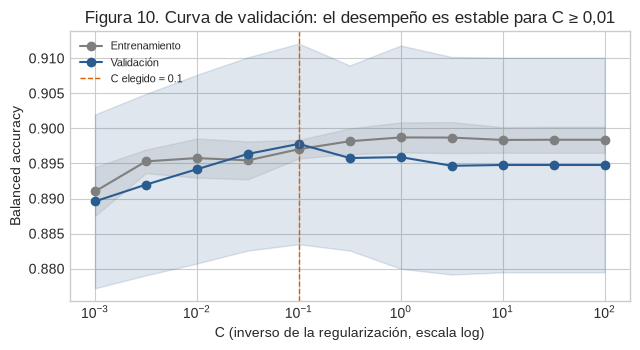

,C,Entrenamiento,Validación (media),Validación (desv)
0,0.0010,0.8910,0.8896,0.0124
1,0.0032,0.8953,0.8920,0.0129
2,0.0100,0.8958,0.8942,0.0135
3,0.0316,0.8954,0.8964,0.0138
4,0.1000,0.8970,0.8978,0.0143
5,0.3162,0.8982,0.8958,0.0132
6,1.0000,0.8987,0.8959,0.0159
7,3.1623,0.8987,0.8947,0.0155
8,10.0000,0.8984,0.8948,0.0153
9,31.6228,0.8984,0.8948,0.0153


In [4]:
def make_pipe(C=1.0):
    return Pipeline([("imputer", SimpleImputer(strategy="median")),
                     ("scaler", StandardScaler()),
                     ("classifier", LogisticRegression(C=C, class_weight="balanced", max_iter=2000))])

gs = GridSearchCV(make_pipe(), {"classifier__C": [0.01, 0.1, 1, 10]}, cv=cv5, scoring="balanced_accuracy")
gs.fit(X_train, y_train)
C_final = gs.best_params_["classifier__C"]
print(f"C elegido: {C_final}  |  balanced accuracy CV (5 pliegues): {gs.best_score_:.4f}")

Cs = np.logspace(-3, 2, 11)
tr, va = validation_curve(make_pipe(), X_train, y_train, param_name="classifier__C", param_range=Cs,
                          cv=cv5, scoring="balanced_accuracy")
fig, ax = plt.subplots(figsize=(6.5, 3.6))
for m, nombre, color in [(tr, "Entrenamiento", "#7f7f7f"), (va, "Validación", "#2b5c8f")]:
    ax.plot(Cs, m.mean(1), marker="o", label=nombre, color=color)
    ax.fill_between(Cs, m.mean(1) - m.std(1), m.mean(1) + m.std(1), alpha=0.15, color=color)
ax.axvline(C_final, color="#d95f02", ls="--", lw=1, label=f"C elegido = {C_final}")
ax.set(xscale="log", xlabel="C (inverso de la regularización, escala log)", ylabel="Balanced accuracy",
       title="Figura 10. Curva de validación: el desempeño es estable para C ≥ 0,01")
ax.legend(fontsize=8)
plt.tight_layout(); plt.savefig(FIGS / "fig10_curva_validacion_C.png", dpi=300); plt.show()
pd.DataFrame({"C": Cs, "Entrenamiento": tr.mean(1), "Validación (media)": va.mean(1),
              "Validación (desv)": va.std(1)}).round(4)

## 3. Umbral de decisión (sin usar la prueba)
Por defecto un clasificador marca "incumple" si su probabilidad supera 0,5. Ese corte no tiene por qué ser el mejor.
Siguiendo el procedimiento de la semana 14 del curso, el umbral se elige **con datos que no son de prueba**: las
probabilidades *out-of-fold* del entrenamiento (cada registro recibe la predicción de un modelo que no lo vio, con los
mismos 5 pliegues). Se busca en una rejilla de 0,20 a 0,80 el umbral que maximiza la balanced accuracy.

Umbral elegido: 0.44  |  balanced accuracy OOF: 0.9000  (con 0,50: 0.8978)


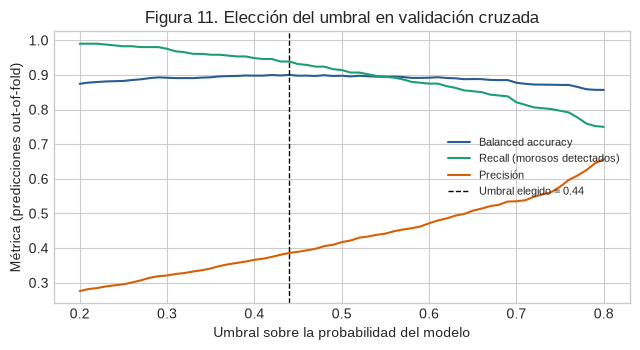

In [5]:
modelo_final = make_pipe(C_final)
p_oof = cross_val_predict(modelo_final, X_train, y_train, cv=cv5, method="predict_proba")[:, 1]
umbrales = np.round(np.linspace(0.20, 0.80, 61), 2)
curva = pd.DataFrame({"umbral": umbrales,
                      "Balanced accuracy": [balanced_accuracy_score(y_train, p_oof >= u) for u in umbrales],
                      "Recall (morosos detectados)": [recall_score(y_train, p_oof >= u) for u in umbrales],
                      "Precisión": [precision_score(y_train, p_oof >= u) for u in umbrales]})
umbral = float(curva.loc[curva["Balanced accuracy"].idxmax(), "umbral"])
ba_05 = curva.loc[curva.umbral == 0.5, "Balanced accuracy"].item()
print(f"Umbral elegido: {umbral:.2f}  |  balanced accuracy OOF: {curva['Balanced accuracy'].max():.4f}  (con 0,50: {ba_05:.4f})")

fig, ax = plt.subplots(figsize=(6.5, 3.6))
for col, color in [("Balanced accuracy", "#2b5c8f"), ("Recall (morosos detectados)", "#1b9e77"), ("Precisión", "#d95f02")]:
    ax.plot(curva.umbral, curva[col], label=col, color=color)
ax.axvline(umbral, color="black", ls="--", lw=1, label=f"Umbral elegido = {umbral:.2f}")
ax.set(xlabel="Umbral sobre la probabilidad del modelo", ylabel="Métrica (predicciones out-of-fold)",
       title="Figura 11. Elección del umbral en validación cruzada")
ax.legend(fontsize=8, loc="center right")
plt.tight_layout(); plt.savefig(FIGS / "fig11_eleccion_umbral.png", dpi=300); plt.show()

## 4. Evaluación única en el conjunto de prueba
El modelo se reentrena con todo el entrenamiento y se evalúa **una sola vez** en la prueba, con el umbral elegido en la
sección 3 (y, como referencia, con 0,5).

,Balanced accuracy,Accuracy,Recall,Precisión,F1,ROC-AUC,Morosos detectados,Falsas alarmas
Umbral 0.44 (elegido),0.8974,0.8692,0.9314,0.3878,0.5476,0.9628,95 de 102,150
"Umbral 0,50 (referencia)",0.8994,0.8892,0.9118,0.4286,0.5831,0.9628,93 de 102,124


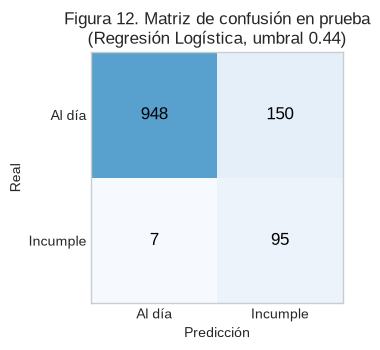

In [6]:
modelo_final.fit(X_train, y_train)
p_test = modelo_final.predict_proba(X_test)[:, 1]

def metricas(y_true, pred, score):
    tn, fp, fn, tp = confusion_matrix(y_true, pred).ravel()
    return {"Balanced accuracy": balanced_accuracy_score(y_true, pred), "Accuracy": accuracy_score(y_true, pred),
            "Recall": recall_score(y_true, pred), "Precisión": precision_score(y_true, pred),
            "F1": f1_score(y_true, pred), "ROC-AUC": roc_auc_score(y_true, score),
            "Morosos detectados": f"{tp} de {tp + fn}", "Falsas alarmas": int(fp)}

eval_test = pd.DataFrame({f"Umbral {umbral:.2f} (elegido)": metricas(y_test, p_test >= umbral, p_test),
                          "Umbral 0,50 (referencia)": metricas(y_test, p_test >= 0.5, p_test)}).T
for c in eval_test.columns[:6]:
    eval_test[c] = eval_test[c].astype(float).round(4)
eval_test.to_csv(TABLES / "tabla5_modelo_final_prueba.csv")
display(eval_test)

fig, ax = plt.subplots(figsize=(4.2, 3.6))
cm = confusion_matrix(y_test, p_test >= umbral)
ConfusionMatrixDisplay(cm, display_labels=["Al día", "Incumple"]).plot(
    ax=ax, cmap="Blues", colorbar=False, values_format="d", im_kw={"vmin": 0, "vmax": cm.max() * 1.8},
    text_kw={"color": "black", "fontsize": 12})
ax.set(title=f"Figura 12. Matriz de confusión en prueba\n(Regresión Logística, umbral {umbral:.2f})",
       xlabel="Predicción", ylabel="Real")
ax.grid(False)
plt.tight_layout(); plt.savefig(FIGS / "fig12_matriz_confusion_final.png", dpi=300); plt.show()

## 5. Contraste con el artículo
Koshti et al. (2025) reportan **accuracy** con una sola partición 80/20; aquí la métrica principal es la balanced accuracy
con CV anidada. Para comparar en la misma moneda se incluye también la accuracy del modelo final en prueba.

In [7]:
articulo = pd.DataFrame({
    "Modelo": ["Random Forest", "XGBoost", "LightGBM", "Gradient Boosting", "SVM", "Regresión Logística",
               "AdaBoost", "Árbol de Decisión", "Naïve Bayes"],
    "Artículo: German (accuracy)": [0.8889, 0.8851, 0.8774, 0.8621, 0.8621, 0.8506, 0.8506, 0.7433, 0.7203],
    "Artículo: Australian (accuracy)": [0.9058, 0.8841, 0.8551, 0.8841, 0.8551, 0.8551, 0.8551, 0.8333, 0.8478],
})
nuestro = tabla3.set_index("Modelo")[["CV anidada Bal. Acc (media)", "CV anidada Bal. Acc (desv)"]]
contraste = articulo.set_index("Modelo").join(nuestro.rename(columns={
    "CV anidada Bal. Acc (media)": "Este proyecto: CV anidada (bal. acc.)",
    "CV anidada Bal. Acc (desv)": "Este proyecto: desviación"}))
contraste["Rango en el artículo (German)"] = contraste["Artículo: German (accuracy)"].rank(ascending=False, method="min").astype(int)
contraste["Rango en este proyecto"] = contraste["Este proyecto: CV anidada (bal. acc.)"].rank(ascending=False, method="min").astype(int)
contraste.round(4).to_csv(TABLES / "tabla6_contraste_articulo.csv")
contraste.round(4)

,Artículo: German (accuracy),Artículo: Australian (accuracy),Este proyecto: CV anidada (bal. acc.),Este proyecto: desviación,Rango en el artículo (German),Rango en este proyecto
Modelo,,,,,,
Random Forest,0.8889,0.9058,0.8909,0.0109,1,3
XGBoost,0.8851,0.8841,0.8905,0.0102,2,5
LightGBM,0.8774,0.8551,0.8908,0.0096,3,4
Gradient Boosting,0.8621,0.8841,0.8878,0.0066,4,6
SVM,0.8621,0.8551,0.8912,0.0049,4,2
Regresión Logística,0.8506,0.8551,0.8924,0.0082,6,1
AdaBoost,0.8506,0.8551,0.8797,0.0154,6,7
Árbol de Decisión,0.7433,0.8333,0.8572,0.0155,8,8
Naïve Bayes,0.7203,0.8478,0.7835,0.0245,9,9


| Aspecto | Artículo (Koshti et al., 2025) | Este proyecto |
|---|---|---|
| Datos | Reales: Kaggle (3 clases), Australian y German (binarios) | Simulación calibrada con DANE y Superfinanciera, binaria, 8,5 % de mora |
| Modelos | 9 | Los mismos 9 |
| Desbalance | Reconocido, sin tratamiento | Pesos de clase en los 9 modelos y balanced accuracy |
| Validación | Una partición 80/20 | CV anidada 5 × 3 y prueba independiente usada una vez |
| Ajuste de hiperparámetros | Sin detalle | GridSearch para todos; Grid, Random y Optuna comparados (notebook 04) |
| Umbral de decisión | 0,5 implícito | Elegido en validación cruzada |
| Resultado | Random Forest primero en los 3 datasets | Siete modelos empatados; Regresión Logística elegida por parsimonia |
| Coincidencias | — | Naïve Bayes y el árbol individual son los más débiles; los ensambles superan al árbol |

## 6. Probabilidades interpretables para el despliegue
Con `class_weight="balanced"` el modelo aprende como si la mora fuera del 50 %, así que su "probabilidad" sobrestima el
riesgo real (la mora es del 8,5 %). Para mostrar una **probabilidad estimada de mora** en la aplicación se corrige el
cambio de proporciones con la fórmula de ajuste de *prior*:

`odds reales = odds del modelo × (0,085 / 0,915) / (0,5 / 0,5)`

La corrección es monótona: no cambia el orden de los clientes ni la decisión, solo la escala en la que se muestra el riesgo.
Se verifica que, en la prueba, la probabilidad corregida promedio se parezca a la tasa de mora observada.

In [8]:
PRIOR = float(y_train.mean())

def prob_corregida(p, prior=PRIOR):
    odds = p / (1 - p) * prior / (1 - prior)
    return odds / (1 + odds)

seg = np.where(X_test["es_informal"] == 1, "Informal", "Formal")
cal = pd.DataFrame({"segmento": seg, "real": y_test.values, "prob_modelo": p_test, "prob_corregida": prob_corregida(p_test)})
resumen = cal.groupby("segmento")[["real", "prob_modelo", "prob_corregida"]].mean()
resumen.loc["Total"] = cal[["real", "prob_modelo", "prob_corregida"]].mean()
umbral_corregido = float(prob_corregida(umbral))
print(f"Umbral {umbral:.2f} en escala del modelo = {umbral_corregido:.1%} de probabilidad estimada de mora")
resumen.rename(columns={"real": "Mora observada", "prob_modelo": "Prob. del modelo (balanceada)",
                        "prob_corregida": "Prob. corregida"}).round(4)

Umbral 0.44 en escala del modelo = 6.8% de probabilidad estimada de mora


,Mora observada,Prob. del modelo (balanceada),Prob. corregida
segmento,,,
Formal,0.0019,0.0031,0.0003
Informal,0.1483,0.3531,0.1362
Total,0.0850,0.2017,0.0774


## 7. Artefactos para el despliegue
Como en la semana 14 del curso, se guardan tres archivos en `modelos/`:

| Archivo | Contenido |
|---|---|
| `modelo_final.joblib` | El Pipeline completo (imputación, escalado y Regresión Logística) entrenado con todo el entrenamiento |
| `modelo_final_metadata.json` | Orden de las variables, **contrato de entrada** (mínimo, máximo, mediana, tipo y valores permitidos, calculados solo con entrenamiento), variable derivada, umbral, *prior*, métricas, versiones y limitaciones |
| `prediccion_referencia.json` | Un solicitante de la prueba con su probabilidad, para verificar que el modelo cargado desde disco predice igual |

In [9]:
contrato = {}
for col in X_train.columns:
    s = X_train[col].dropna()
    entero = bool(np.allclose(s, s.round()))
    contrato[col] = {"min": float(s.min()), "max": float(s.max()), "mediana": float(s.median()), "entero": entero}
contrato["es_informal"]["valores"] = [0, 1]
contrato["plazo_meses"]["valores"] = sorted(int(v) for v in X_train["plazo_meses"].unique())

metadata = {
    "modelo": "Regresión Logística (class_weight='balanced') en Pipeline: SimpleImputer(median) -> StandardScaler",
    "hiperparametros": {"C": C_final, "max_iter": 2000},
    "orden_variables": list(X_train.columns),
    "contrato_entrada": contrato,
    "variable_derivada": {"relacion_cuota_ingreso": "((monto_credito_smmlv / plazo_meses) * 1.2) / max(ingreso_smmlv, 0.5), redondeada a 3 decimales"},
    "umbral_decision": umbral,
    "umbral_decision_probabilidad_corregida": round(umbral_corregido, 6),
    "prior_mora_entrenamiento": PRIOR,
    "metricas": {"cv_anidada_balanced_accuracy": float(tabla3.set_index("Modelo").loc["Regresión Logística", "CV anidada Bal. Acc (media)"]),
                 "cv5_balanced_accuracy": float(gs.best_score_),
                 "prueba": {k: (v if isinstance(v, str) else float(v)) for k, v in eval_test.iloc[0].items()}},
    "versiones": {"python": platform.python_version(), "scikit-learn": sklearn.__version__,
                  "numpy": np.__version__, "pandas": pd.__version__},
    "semilla": SEED,
    "limitaciones": [
        "Entrenado con datos simulados (6.000 solicitantes); no usar para decisiones reales sin validación con datos reales.",
        "La mora se simuló con un logit, lo que favorece a un modelo lineal.",
        "La mora del segmento formal es casi nula en la simulación: el modelo casi no rechaza formales y concentra las falsas alarmas en informales.",
        "La explicación por contribuciones describe el modelo, no relaciones causales.",
    ],
}
joblib.dump(modelo_final, MODELS / "modelo_final.joblib")
(MODELS / "modelo_final_metadata.json").write_text(json.dumps(metadata, ensure_ascii=False, indent=2), encoding="utf-8")

ref = X_test[(X_test.es_informal == 1) & X_test.notna().all(axis=1)].iloc[[0]]
p_ref = float(modelo_final.predict_proba(ref)[:, 1][0])
referencia = {"entrada": {k: (None if pd.isna(v) else float(v)) for k, v in ref.iloc[0].items()},
              "probabilidad_modelo": p_ref, "probabilidad_corregida": float(prob_corregida(p_ref)),
              "decision": "Rechazar (riesgo alto)" if p_ref >= umbral else "Aprobar",
              "tolerancia": 1e-6}
(MODELS / "prediccion_referencia.json").write_text(json.dumps(referencia, ensure_ascii=False, indent=2), encoding="utf-8")
print(json.dumps(referencia, ensure_ascii=False, indent=2))

{
  "entrada": {
    "edad": 27.0,
    "es_informal": 1.0,
    "antiguedad_laboral": 1.9,
    "ingreso_smmlv": 1.92,
    "monto_credito_smmlv": 2.57,
    "plazo_meses": 60.0,
    "creditos_activos": 2.0,
    "moras_previas": 0.0,
    "score_crediticio": 490.0,
    "relacion_cuota_ingreso": 0.027
  },
  "probabilidad_modelo": 0.32481900473235686,
  "probabilidad_corregida": 0.042779060630766017,
  "decision": "Aprobar",
  "tolerancia": 1e-06
}


### 7.1 Verificación: el artefacto guardado predice igual que el modelo en memoria

In [10]:
cargado = joblib.load(MODELS / "modelo_final.joblib")
meta = json.loads((MODELS / "modelo_final_metadata.json").read_text(encoding="utf-8"))
ref_json = json.loads((MODELS / "prediccion_referencia.json").read_text(encoding="utf-8"))
entrada = pd.DataFrame([ref_json["entrada"]])[meta["orden_variables"]]
p_cargado = float(cargado.predict_proba(entrada)[:, 1][0])
assert abs(p_cargado - ref_json["probabilidad_modelo"]) <= ref_json["tolerancia"]
assert np.allclose(cargado.predict_proba(X_test)[:, 1], p_test)
print(f"✔ Probabilidad de referencia reproducida: {p_cargado:.6f}  |  predicciones de prueba idénticas")

✔ Probabilidad de referencia reproducida: 0.324819  |  predicciones de prueba idénticas


## 8. Lectura

**1. Modelo final: Regresión Logística con `C = 0,1` y `class_weight='balanced'`.** Tiene la mayor balanced accuracy en
CV anidada (0,892 ± 0,008) entre siete modelos empatados, y ante el empate se elige el más simple e interpretable.

**2. La configuración es estable.** En la curva de validación (Figura 10), la balanced accuracy de validación se mueve
entre 0,894 y 0,898 para cualquier C entre 0,01 y 100, una diferencia menor que la desviación entre pliegues (≈ 0,014).
Por eso en el notebook 03 el C elegido cambiaba de un pliegue a otro sin afectar el desempeño: C no es crítico.

**3. El umbral casi no cambia nada.** El umbral elegido en validación cruzada es 0,44, con una ganancia mínima frente a
0,50 (0,900 frente a 0,898 en las predicciones *out-of-fold*). Con pesos balanceados, 0,50 ya está cerca del óptimo. En
la prueba, 0,44 detecta 2 morosos más (95 frente a 93 de 102) a cambio de 26 falsas alarmas más, con una balanced
accuracy similar (0,897 frente a 0,899). Se mantiene 0,44 porque fue el procedimiento declarado: elegir el umbral
mirando la prueba sería una forma de fuga. En la práctica, el banco fijaría el umbral según lo que le cuesta cada error.

**4. Desempeño en prueba (umbral 0,44).** Balanced accuracy 0,897; detecta el 93 % de los morosos (95 de 102); ROC-AUC
0,963; precisión 0,39 (de cada 100 alertas, 39 son morosos reales). Su accuracy (0,869) está en el rango que reporta el
artículo (85–91 %), aunque allí se midió con una sola partición y sin tratar el desbalance.

**5. Contraste con el artículo.** *Se reprodujo:* la comparación de los mismos nueve modelos; Naïve Bayes y el árbol
individual quedan últimos, como en el dataset alemán del artículo (rangos 8 y 9). *Se adaptó:* datos colombianos
simulados, tratamiento del desbalance, CV anidada, búsqueda de hiperparámetros y umbral. *Fue diferente:* Random Forest
no se distingue de los demás ensambles ni de la Regresión Logística (sexta en el artículo, primera aquí). La razón
principal es que la mora se simuló con un logit; además, la ventaja del artículo proviene de una sola partición y, en el
dataset alemán, posiblemente de un sobremuestreo previo a la partición.

**6. Probabilidades para el despliegue.** Corregida por el *prior* de 8,5 %, la probabilidad promedio del modelo en la
prueba (7,7 %) queda cerca de la mora observada (8,5 %), también por segmento (informales: 13,6 % frente a 14,8 %). La
aplicación mostrará esta probabilidad corregida; el umbral 0,44 equivale a una probabilidad estimada de mora de 6,8 %.

**7. Artefactos listos.** `modelos/` contiene el Pipeline entrenado, su contrato de entrada y una predicción de
referencia; se verificó que el modelo cargado desde disco predice exactamente igual. Son la base de la interpretación
(8.2) y de la aplicación (8.3).